<a href="https://colab.research.google.com/github/atlangelreyes32-creator/Modelado_y_Simulacion_Mecatronicos/blob/main/PIA_MODELADO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

## Universidad Autónoma de Nuevo León
### Facultad de Ingeniería Mecánica y Eléctrica

## Modelado y simulación de sistemas mecatrónicos
### PIA

</div>

**Catedrático:** DANIEL ISAÍAS LÓPEZ PÁEZ

**Nombres:**

Guillermo Daniel Amador Salazar - 2226711  
Eduardo Andree González Martínez - 2159118  
Angel Gabriel Reyes García - 2066393  
Martín Castruita Flores - 2144141  

**Día y Hora:** Martes N1-N3

San Nicolás de los Garza, N.L., México

14 de Noviembre del 2026

Estado de la integración: The solver successfully reached the end of the integration interval.
q1(10 s) = 52.70°,  q2(10 s) = -28.24°


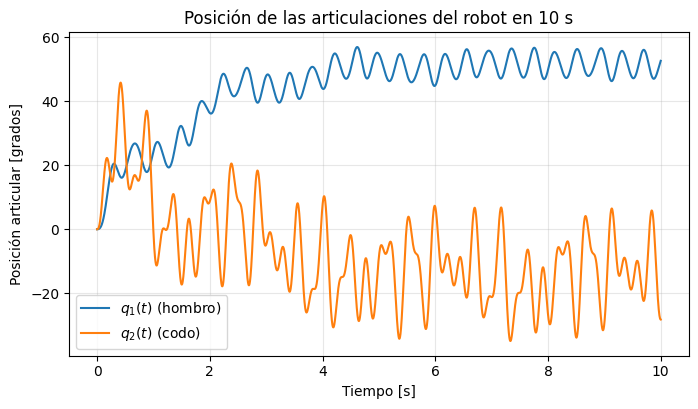

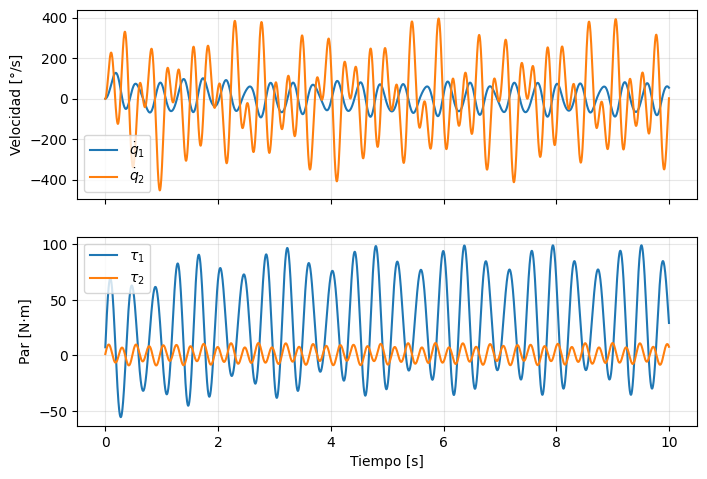

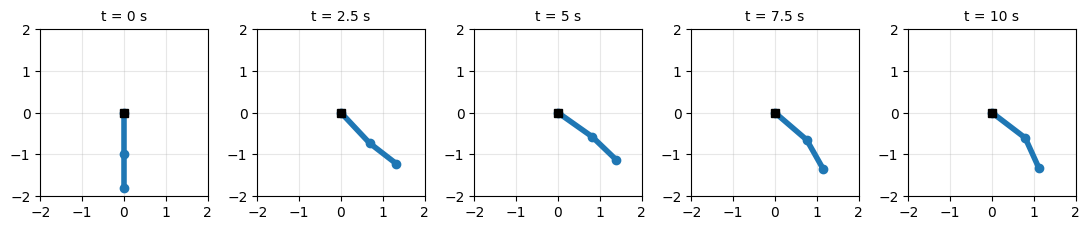

In [1]:
# ============================================================
# Universidad Autónoma de Nuevo León
# Facultad de Ingeniería Mecánica y Eléctrica
#
# Modelado y simulación de sistemas mecatrónicos
# AF 3.- Simulación numérica e interpretación del comportamiento dinámico.
#
# Catedrático: DANIEL ISAÍAS LÓPEZ PÁEZ
#
# Nombres:
#   Guillermo Daniel Amador Salazar - 2226711
#   Eduardo Andree González Martínez - 2159118
#   Angel Gabriel Reyes García - 2066393
#   Martín Castruita Flores - 2144141
#
# Día y Hora: Martes N1-N3
# San Nicolás de los Garza, N.L., México
# 13 de Noviembre del 2026
# ============================================================

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Parámetros agregados del robot
a1, a2, a3 = 3.117, 0.1, 0.108      # inercia
g1, g2     = 39.3, 1.95             # gravedad
bv = np.array([1.86, 0.16])         # fricción viscosa   [N·m·s/rad]
fc = np.array([1.93, 0.30])         # fricción de Coulomb [N·m]
L1, L2 = 1.0, 0.8                   # longitudes (solo para dibujar el brazo)

def signo(v, k=1000.0):
    return np.tanh(k * v)          # aproximación suave de sign(v)

def M(q):
    c = np.cos(q[1])
    return np.array([[a1 + 2*a2*c, a3 + a2*c],
                     [a3 + a2*c,   a3       ]])

def C(q, qd):
    s = np.sin(q[1])
    return np.array([[-2*a2*s*qd[1], -a2*s*qd[1]],
                     [  a2*s*qd[0],   0.0       ]])

def G(q):
    return np.array([g1*np.sin(q[0]) + g2*np.sin(q[0] + q[1]),
                     g2*np.sin(q[0] + q[1])])

def F(qd):
    return bv*qd + fc*signo(qd)

def tau(t):
    t1 = (1-np.exp(-0.8*t))*32.0 + 56*np.sin(16*t+0.1) + 12*np.sin(20*t+0.15)
    t2 = (1-np.exp(-1.8*t))*1.2  + 8*np.sin(26*t+0.08) + 2*np.sin(12*t+0.34)
    return np.array([t1, t2])

def robot2gdl(t, x):
    q, qd = x[:2], x[2:]
    qdd = np.linalg.solve(M(q), tau(t) - C(q, qd) @ qd - G(q) - F(qd))
    return np.concatenate([qd, qdd])

ti, tf, h = 0.0, 10.0, 0.0025
ts = np.arange(ti, tf + h, h)
sol = solve_ivp(robot2gdl, (ti, tf), [0, 0, 0, 0], t_eval=ts,
                method="LSODA", rtol=1e-6, atol=1e-8, max_step=h)
t  = sol.t
q  = np.degrees(sol.y[:2])        # posiciones [grados]
qd = np.degrees(sol.y[2:])        # velocidades [grados/s]
print("Estado de la integración:", sol.message)
print(f"q1(10 s) = {q[0,-1]:.2f}°,  q2(10 s) = {q[1,-1]:.2f}°")

# Gráfica 1: posición articular
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(t, q[0], label=r"$q_1(t)$ (hombro)")
ax.plot(t, q[1], label=r"$q_2(t)$ (codo)")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("Posición articular [grados]")
ax.set_title("Posición de las articulaciones del robot en 10 s")
ax.grid(alpha=.3); ax.legend(); plt.show()

# Gráfica 2: velocidades y pares
T = np.array([tau(x) for x in t])
fig, ax = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
ax[0].plot(t, qd[0], label=r"$\dot q_1$"); ax[0].plot(t, qd[1], label=r"$\dot q_2$")
ax[0].set_ylabel("Velocidad [°/s]"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(t, T[:,0], label=r"$\tau_1$"); ax[1].plot(t, T[:,1], label=r"$\tau_2$")
ax[1].set_ylabel("Par [N·m]"); ax[1].set_xlabel("Tiempo [s]"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

# Gráfica 3: capturas del brazo
def brazo(k):
    a1_, a2_ = sol.y[0,k], sol.y[0,k] + sol.y[1,k]
    p1 = L1*np.array([np.sin(a1_), -np.cos(a1_)])
    p2 = p1 + L2*np.array([np.sin(a2_), -np.cos(a2_)])
    return [0, p1[0], p2[0]], [0, p1[1], p2[1]]

fig, axs = plt.subplots(1, 5, figsize=(11, 2.8))
for a, tt in zip(axs, [0, 2.5, 5, 7.5, 10]):
    xs, ys = brazo(int(round(tt/h)))
    a.plot(xs, ys, "-o", lw=4); a.plot(0, 0, "ks")
    a.set_xlim(-2, 2); a.set_ylim(-2, 2); a.set_aspect("equal")
    a.set_title(f"t = {tt:g} s", fontsize=10); a.grid(alpha=.3)
plt.tight_layout(); plt.show()